# Business Problem: Predicting Hospital LOS
Hospitals have a limited number of beds and healthcare resources, so longer patient stays
can reduce the availability of these resources for other patients. The goal of this project is
to predict how long a patient is likely to stay in the hospital and identify patients who are
at risk of having an extended stay early enough for healthcare teams to begin discharge
planning and make the necessary arrangements. The project will therefore look at the
problem in two ways: predicting the patient's expected length of stay in days
(regression) and classifying whether the patient is likely to have an extended stay
(classification). The definition of an extended stay will be based on a predefined
length-of-stay threshold that will be determined from the available data.

## Data Sources
* Hospital Length of Stay Dataset – Microsoft (Kaggle) (https://www.kaggle.com/datasets/aayushchou/hospital-length-of-stay-dataset-microsoft)
* Microsoft – Predicting Hospital Length of Stay: Input Data (https://microsoft.github.io/r-server-hospital-length-of-stay/input_data.html)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.linear_model import LinearRegression
from sklearn import linear_model
pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_csv('LengthOfStay.csv')

# Data Understanding
This section describes the hospital length-of-stay dataset: its size, columns, data types, and the target variables. It then checks data quality, summarizes distributions, examines outliers, and explores how the target relates to the inputs, before finalizing preprocessing for modeling.






## 1. Dataset overview
Load the dataset to inspect its size, review column names and data types, identify target
and input features.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  object 
 2   rcount                      100000 non-null  object 
 3   gender                      100000 non-null  object 
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma                      100000 non-null  int64  
 6   irondef                     100000 non-null  int64  
 7   pneum                       100000 non-null  int64  
 8   substancedependence         100000 non-null  int64  
 9   psychologicaldisordermajor  100000 non-null  int64  
 10  depress                     100000 non-null  int64  
 11  psychother                  100000 non-null  int64  
 12  fibrosisandother            100000 non-null  int64  
 13  malnutrition   

We have 100000 rows of patient data. The column names and what they describe is listed below:

| Index | Data Field | Type | Description |
|---:|---|---|---|
| 0 | `eid` | Integer (`int64`) | Unique ID of the hospital admission |
| 1 | `vdate` | String (`object`) | Visit date |
| 2 | `rcount` | String (`object`) | Number of readmissions within the last 180 days |
| 3 | `gender` | String (`object`) | Gender of the patient (M or F) |
| 4 | `dialysisrenalendstage` | Integer (`int64`) | Flag for renal disease during the encounter |
| 5 | `asthma` | Integer (`int64`) | Flag for asthma during the encounter |
| 6 | `irondef` | Integer (`int64`) | Flag for iron deficiency during the encounter |
| 7 | `pneum` | Integer (`int64`) | Flag for pneumonia during the encounter |
| 8 | `substancedependence` | Integer (`int64`) | Flag for substance dependence during the encounter |
| 9 | `psychologicaldisordermajor` | Integer (`int64`) | Flag for major psychological disorder during the encounter |
| 10 | `depress` | Integer (`int64`) | Flag for depression during the encounter |
| 11 | `psychother` | Integer (`int64`) | Flag for other psychological disorder during the encounter |
| 12 | `fibrosisandother` | Integer (`int64`) | Flag for fibrosis during the encounter |
| 13 | `malnutrition` | Integer (`int64`) | Flag for malnutrition during the encounter |
| 14 | `hemo` | Integer (`int64`) | Flag for blood disorder during the encounter |
| 15 | `hematocrit` | Float (`float64`) | Average hematocrit value during the encounter (g/dL) |
| 16 | `neutrophils` | Float (`float64`) | Average neutrophils value during the encounter (cells/microL) |
| 17 | `sodium` | Float (`float64`) | Average sodium value during the encounter (mmol/L) |
| 18 | `glucose` | Float (`float64`) | Average glucose value during the encounter (mg/dL) |
| 19 | `bloodureanitro` | Float (`float64`) | Average blood urea nitrogen value during the encounter (mg/dL) |
| 20 | `creatinine` | Float (`float64`) | Average creatinine value during the encounter (mg/dL) |
| 21 | `bmi` | Float (`float64`) | Average BMI during the encounter (kg/m²) |
| 22 | `pulse` | Integer (`int64`) | Average pulse during the encounter (beats/min) |
| 23 | `respiration` | Float (`float64`) | Average respiration during the encounter (breaths/min) |
| 24 | `secondarydiagnosisnonicd9` | Integer (`int64`) | Flag indicating whether a non-ICD-9 formatted diagnosis was coded as a secondary diagnosis |
| 25 | `discharged` | String (`object`) | Date of discharge |
| 26 | `facid` | String (`object`) | Facility ID at which the encounter occurred |
| 27 | `lengthofstay` | Integer (`int64`) | Length of stay for the encounter |

We will use `lengthofstay` as the target variable for regression, and create another column `long_stay` for classification with `6` as the threshold. So, anything above 6 becomes a lengthy stay (1), and anything shorter is not (0).

Input features: rcount, 11 condition flags, 9 lab measurements and secondarydiagnosisnonicd9.

Not used as inputs:

eid: It is just an identifier with no significance.

discharged: discharged - vdate equals length of stay so it would cause data leakage.

vdate: exact visit date is not useful for a patient.

lengthofstay/long_stay: These are the targets


From the above we can see that the feature columns are mostly in the correct format. The two date columns
(`vdate`, `discharged`) are stored as strings and `rcount` is stored as a string because of the `5+` category.

## 2. Data types and feature categorization
Group features into numerical, categorical, temporal, and identifier variables. This will help us in appropriate summary statistics, visualizations, and preprocessing steps.

In [6]:
id_cols = ['eid']
temporal_cols = ['vdate', 'discharged']
flag_cols = ['dialysisrenalendstage', 'asthma', 'irondef', 'pneum', 'substancedependence',
             'psychologicaldisordermajor', 'depress', 'psychother', 'fibrosisandother',
             'malnutrition', 'hemo']
categorical_cols = ['gender', 'facid'] + flag_cols
count_cols = ['rcount', 'secondarydiagnosisnonicd9']
numerical_cols = ['hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro',
                  'creatinine', 'bmi', 'pulse', 'respiration']
target = 'lengthofstay'


groups = id_cols + temporal_cols + categorical_cols + count_cols + numerical_cols + [target]
assert sorted(groups) == sorted(df.columns)
pd.Series({'Identifier': len(id_cols), 'Temporal': len(temporal_cols),
           'Categorical (incl. binary flags)': len(categorical_cols),
           'Discrete count': len(count_cols), 'Numerical (continuous)': len(numerical_cols), 'Target': 1}, name='# columns').to_frame()

,# columns
Identifier,1
Temporal,2
Categorical (incl. binary flags),13
Discrete count,2
Numerical (continuous),9
Target,1


**Identifier:** `eid`

**Temporal:** `vdate`, `discharged`

**Categorical:** `gender`, `facid`, and the 11 binary condition flags `dialysisrenalendstage`, `asthma`, `irondef`, `pneum`, `substancedependence`, `psychologicaldisordermajor`, `depress`, `psychother`, `fibrosisandother`, `malnutrition`, `hemo`

**Discrete count (ordinal):** `rcount` (0 to `5+`), `secondarydiagnosisnonicd9` (0–10)

**Numerical (continuous):** `hematocrit`, `neutrophils`, `sodium`, `glucose`, `bloodureanitro`, `creatinine`, `bmi`, `pulse`, `respiration`

**Target:** `lengthofstay`
rccount is stored as string and is capped at 5+. We will convert it into a numerical value since the value itself has increasing significance.

## 3. Missing data and quality assessment
Examine missing values to assess their extent and impact, identify columns with missing data, calculate the proportion of missing values, evaluate missingness patterns, and decide whether to impute or exclude features to avoid biased or misleading results. Also check for data messiness, including duplicate records, invalid ranges, and inconsistent formats, and correct them as needed.

In [7]:
df.isna().sum()

eid                           0
vdate                         0
rcount                        0
gender                        0
dialysisrenalendstage         0
asthma                        0
irondef                       0
pneum                         0
substancedependence           0
psychologicaldisordermajor    0
depress                       0
psychother                    0
fibrosisandother              0
malnutrition                  0
hemo                          0
hematocrit                    0
neutrophils                   0
sodium                        0
glucose                       0
bloodureanitro                0
creatinine                    0
bmi                           0
pulse                         0
respiration                   0
secondarydiagnosisnonicd9     0
discharged                    0
facid                         0
lengthofstay                  0
dtype: int64

Our dataset does not have any missing values (0% in every column), so there are no missingness patterns to
evaluate and no imputation or feature exclusion is needed for missing data.

In [8]:
print('Duplicate Rows: ', df.duplicated().sum())
print('Duplicate Rows without the ID column: ', df.drop(columns='eid').duplicated().sum())

Duplicate Rows:  0
Duplicate Rows without the ID column:  0


There are no duplicate values with or without the same eid.

In [9]:
for col in ['vdate', 'discharged', 'rcount', 'gender', 'facid']:
    vals = df[col].unique()
    print(f'{col:11s} {len(vals):4d} unique  e.g. {sorted(vals)[:8]}')

vdate        367 unique  e.g. ['1/1/2012', '1/1/2013', '1/10/2012', '1/11/2012', '1/12/2012', '1/13/2012', '1/14/2012', '1/15/2012']
discharged   378 unique  e.g. ['1/1/2013', '1/10/2012', '1/10/2013', '1/11/2012', '1/11/2013', '1/12/2012', '1/12/2013', '1/13/2012']
rcount         6 unique  e.g. ['0', '1', '2', '3', '4', '5+']
gender         2 unique  e.g. ['F', 'M']
facid          5 unique  e.g. ['A', 'B', 'C', 'D', 'E']


In [ ]:
df['vdate'] = pd.to_datetime(df['vdate'], format='%m/%d/%Y')
df['discharged'] = pd.to_datetime(df['discharged'], format='%m/%d/%Y')
df['rcount'] = df['rcount'].replace('5+', '5').astype(int)

print('Visit dates:', df['vdate'].min().date(), 'to', df['vdate'].max().date())
print('Discharge before visit:', (df['discharged'] < df['vdate']).sum())
print('discharged - vdate == lengthofstay:',
      f"{((df['discharged'] - df['vdate']).dt.days == df['lengthofstay']).mean():.0%} of rows")

Visit dates: 2012-01-01 to 2013-01-01
Discharge before visit: 0
discharged - vdate == lengthofstay: 100% of rows


The categorical values are consistent. Gender is only F/M, facilities range from A to E  and readmissions are only 0 to 5+. Dates can be converted cleanly, and there are no discharge before visits, and the lengthofstay is always admitted date - discharge date. So it means that data is consistent.

Every Binary feature should only have 0 or 1.

In [ ]:
print('Flags with values other than 0/1:', [c for c in flag_cols if not df[c].isin([0, 1]).all()])
print('secondarydiagnosisnonicd9 values:', sorted(df['secondarydiagnosisnonicd9'].unique()))

Flags with values other than 0/1: []
secondarydiagnosisnonicd9 values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [ ]:
limits = {'hematocrit': (0, 70), 'neutrophils': (0, 300), 'sodium': (100, 180), 'glucose': (0, 1000),
          'bloodureanitro': (0, 700), 'creatinine': (0, 20), 'bmi': (10, 80), 'pulse': (20, 250),
          'respiration': (0, 60)}
range_check = pd.DataFrame({
    'min': df[numerical_cols].min(),
    'max': df[numerical_cols].max(),
    'allowed': [f'{lo}–{hi}' for lo, hi in limits.values()],
    'n_invalid': [((df[c] < lo) | (df[c] > hi)).sum() for c, (lo, hi) in limits.items()],
})
range_check

,min,max,allowed,n_invalid
hematocrit,4.400000,24.100000,0–70,0
neutrophils,0.100000,245.900000,0–300,0
sodium,124.912632,151.387283,100–180,0
glucose,-1.005927,271.444277,0–1000,1
bloodureanitro,1.000000,682.500000,0–700,0
creatinine,0.219770,2.035202,0–20,0
bmi,21.992683,38.935293,10–80,0
pulse,21.000000,130.000000,20–250,0
respiration,0.200000,10.000000,0–60,0


These are ranges taken from research. Values for the features outside their specific rannge is not possible. We can see that we have negative value for one glucose row.

In [ ]:
print('Most common respiration values:')
print(df['respiration'].value_counts(normalize=True).head(3).round(3))

Most common respiration values:
respiration
6.5    0.648
6.4    0.015
6.2    0.015
Name: proportion, dtype: float64


The values for respiration are suspicious. The median is 6.5 while a normal human respiration rate is 12-20. 65% of rows contain exactly 6.5 which looks like its a default fill value. The column is consistent so we keep it, but treat it with caution.

In [ ]:
df = df[df['glucose'] >= 0].reset_index(drop=True)
print('glucose missing after fix:', df['glucose'].isna().sum())

glucose missing after fix: 0


## 4. Descriptive statistics
Compute summary statistics for numerical variables to examine central tendency, spread, and distribution shape, and use frequency counts for categorical variables to assess class balance and dominant categories.

In [ ]:
desc = df[numerical_cols + [target]].describe().T
desc['median'] = df[numerical_cols + [target]].median()
desc['skew'] = df[numerical_cols + [target]].skew()
desc['kurtosis'] = df[numerical_cols + [target]].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis
hematocrit,99999.0,11.98,2.03,4.40,10.90,11.90,12.90,24.10,11.90,0.56,1.82
neutrophils,99999.0,10.18,5.35,0.10,7.70,9.40,11.50,245.90,9.40,13.28,428.44
sodium,99999.0,137.89,3.00,124.91,135.87,137.89,139.91,151.39,137.89,0.00,0.02
glucose,99999.0,141.96,29.99,11.05,121.68,142.09,162.18,271.44,142.09,-0.01,0.01
bloodureanitro,99999.0,14.10,12.95,1.00,11.00,12.00,14.00,682.50,12.00,17.29,528.55
creatinine,99999.0,1.10,0.20,0.22,0.96,1.10,1.23,2.04,1.10,0.00,-0.01
bmi,99999.0,29.81,2.00,21.99,28.45,29.81,31.16,38.94,29.81,0.01,0.00
pulse,99999.0,73.44,11.64,21.00,66.00,73.00,81.00,130.00,73.00,0.00,0.03
respiration,99999.0,6.49,0.57,0.20,6.50,6.50,6.50,10.00,6.50,-0.55,8.30
lengthofstay,99999.0,4.00,2.36,1.00,2.00,4.00,6.00,17.00,4.00,0.63,-0.02


- `sodium`, `glucose`, `bmi`, `pulse` and `creatinine` are kind of symmetric: their mean and median are almost equal and the skew is close to 0.
- **`neutrophils` and `bloodureanitro` are strongly right-skewed** (skew around 13 and 17, very high kurtosis). Most
  patients have normal values, with a long tail of very high readings.
- `respiration` has very little spread around 6.5

In [ ]:
df[['gender', 'facid']].describe().T

,count,unique,top,freq
gender,99999,2,F,57643
facid,99999,5,E,30755


In [ ]:
df['rcount'].value_counts().sort_index().to_frame('count').assign(pct=lambda t: (t['count'] / len(df) * 100).round(1))

,count,pct
rcount,,
0,55031,55.0
1,15007,15.0
2,9987,10.0
3,8047,8.0
4,6940,6.9
5,4987,5.0


In [ ]:
df['gender'].value_counts().to_frame('count').assign(pct=lambda t: (t['count'] / len(df) * 100).round(1))

,count,pct
gender,,
F,57643,57.6
M,42356,42.4


In [ ]:
df['secondarydiagnosisnonicd9'].value_counts().sort_index().to_frame('count').T

secondarydiagnosisnonicd9,0,1,2,3,4,5,6,7,8,9,10
count,10090,50028,9782,9020,8990,3987,3086,1960,1006,1001,1049


In [ ]:
df['facid'].value_counts().to_frame('count').assign(pct=lambda t: (t['count'] / len(df) * 100).round(1))

,count,pct
facid,,
E,30755,30.8
A,30034,30.0
B,30012,30.0
C,4699,4.7
D,4499,4.5


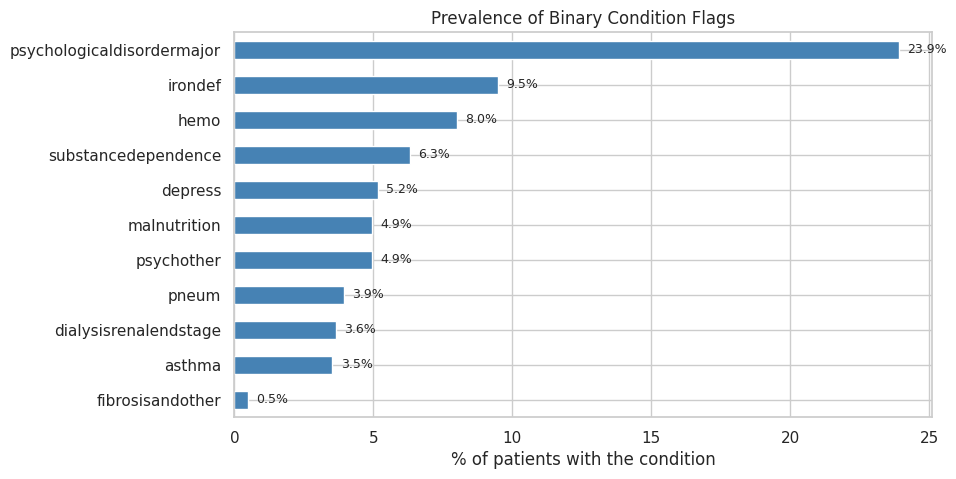

In [ ]:
prevalence = (df[flag_cols].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
prevalence.plot.barh(ax=ax, color='steelblue')
for i, v in enumerate(prevalence):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('% of patients with the condition')
ax.set_title('Prevalence of Binary Condition Flags')
plt.show()

- **`rcount`**: 55% of patients have no readmissions in the last 180 days, and the counts fall steadily for higher values.
- **`gender`**: moderately imbalanced (58% female, 42% male).
- **`secondarydiagnosisnonicd9`**: half of the patients have exactly 1, and 10% have 0.
- **`facid`**: facilities A, B and E each handle about 30% of admissions, while C and D are small (~5% each).
- **Condition flags**: all are minority classes. Major psychological disorder is the most common (24%) and fibrosis
  the rarest (<1%). Rare flags carry little information on their own, so we also create a combined count of
  conditions in Section 7.

## 5. Outliers and data quality checks
Examine outliers using summary statistics and visualizations, and decide whether to retain, cap, or remove them based on domain relevance and business impact.

In [ ]:
# Selecting all numeric columns
los_numeric_cols = numerical_cols

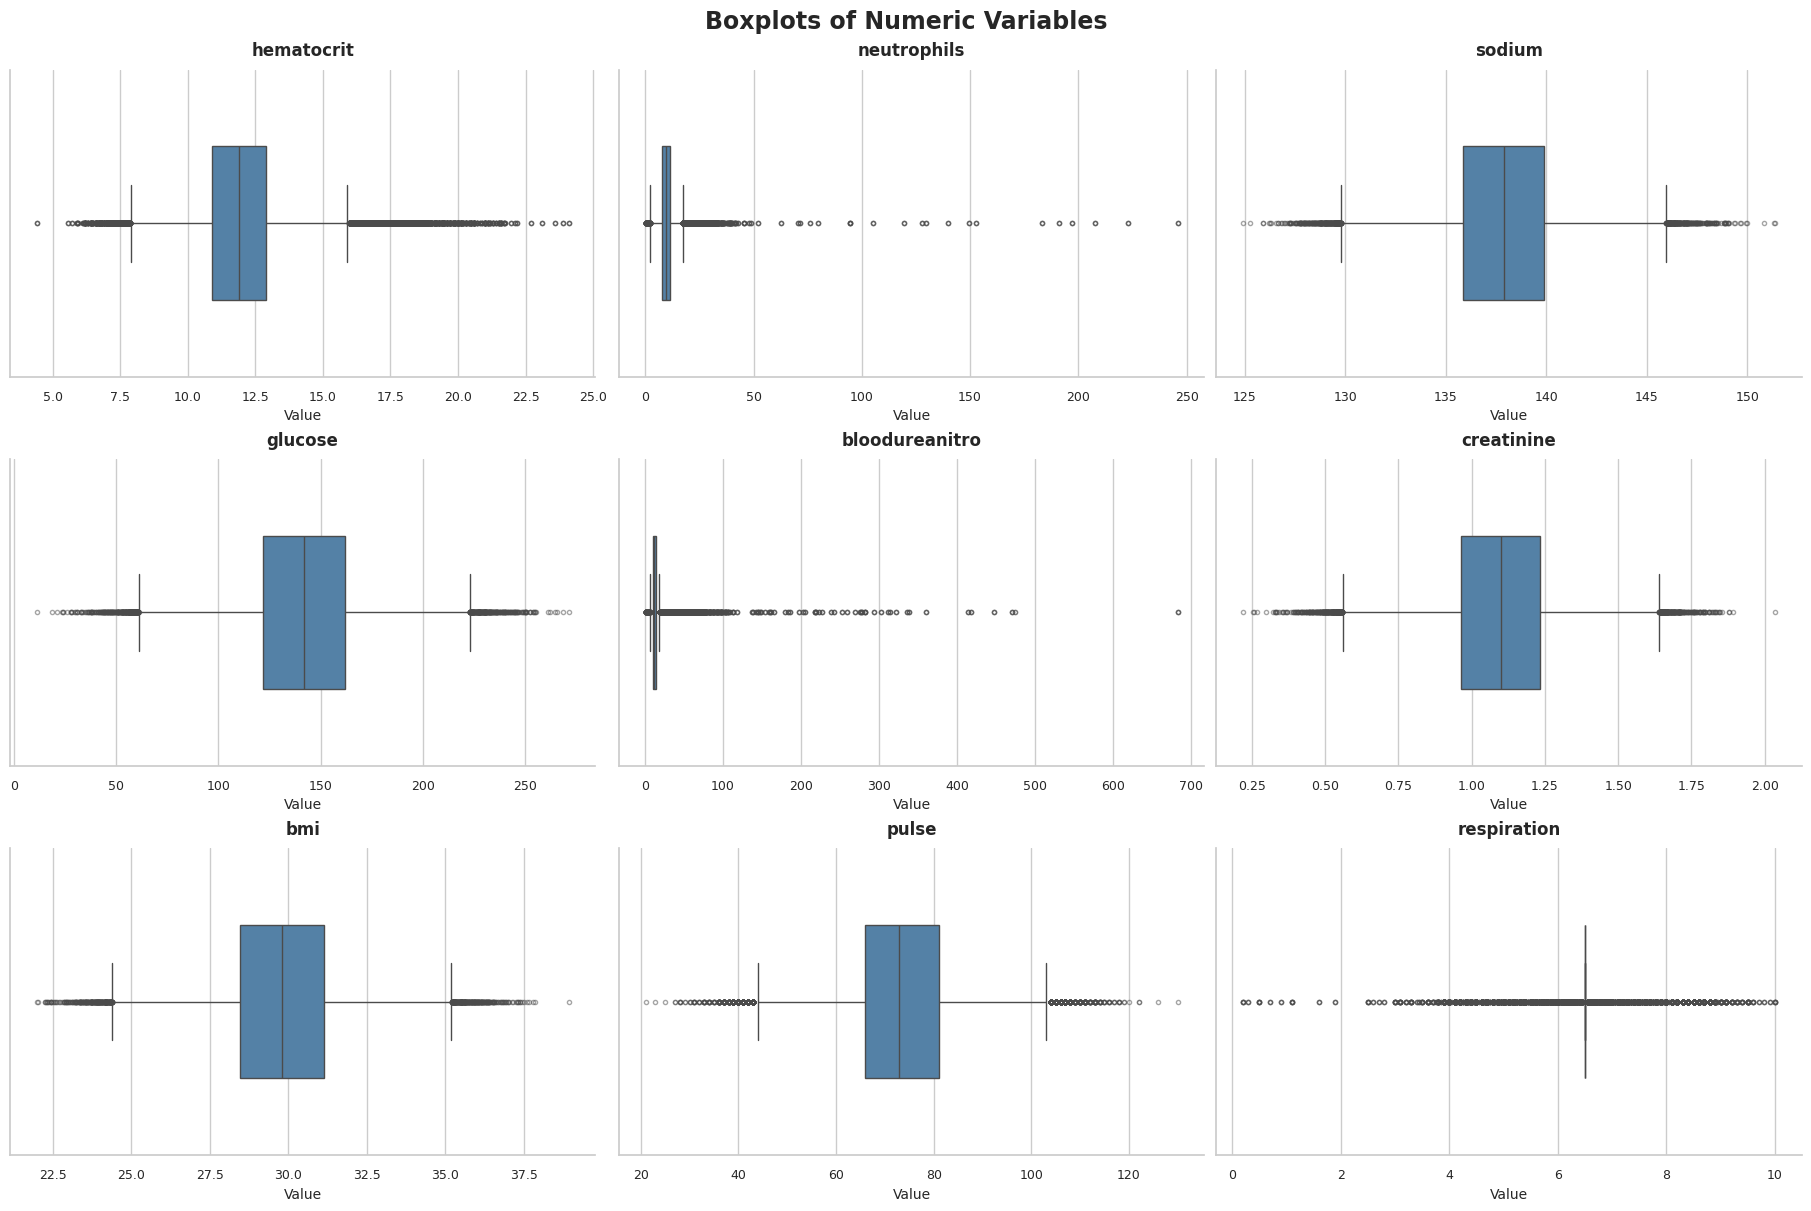

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")

n_cols = 3
n_rows = math.ceil(len(los_numeric_cols) / n_cols)

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(18, 4 * n_rows),
    constrained_layout=True
)

axes = axes.flatten()

for ax, col in zip(axes, los_numeric_cols):
    data = df[col].dropna()

    sns.boxplot(
        x=data,
        ax=ax,
        color="steelblue",
        width=0.5,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        }
    )

    ax.set_title(col, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Value", fontsize=10)
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in axes[len(los_numeric_cols):]:
    ax.set_visible(False)

fig.suptitle(
    "Boxplots of Numeric Variables",
    fontsize=17,
    fontweight="bold"
)

plt.show()


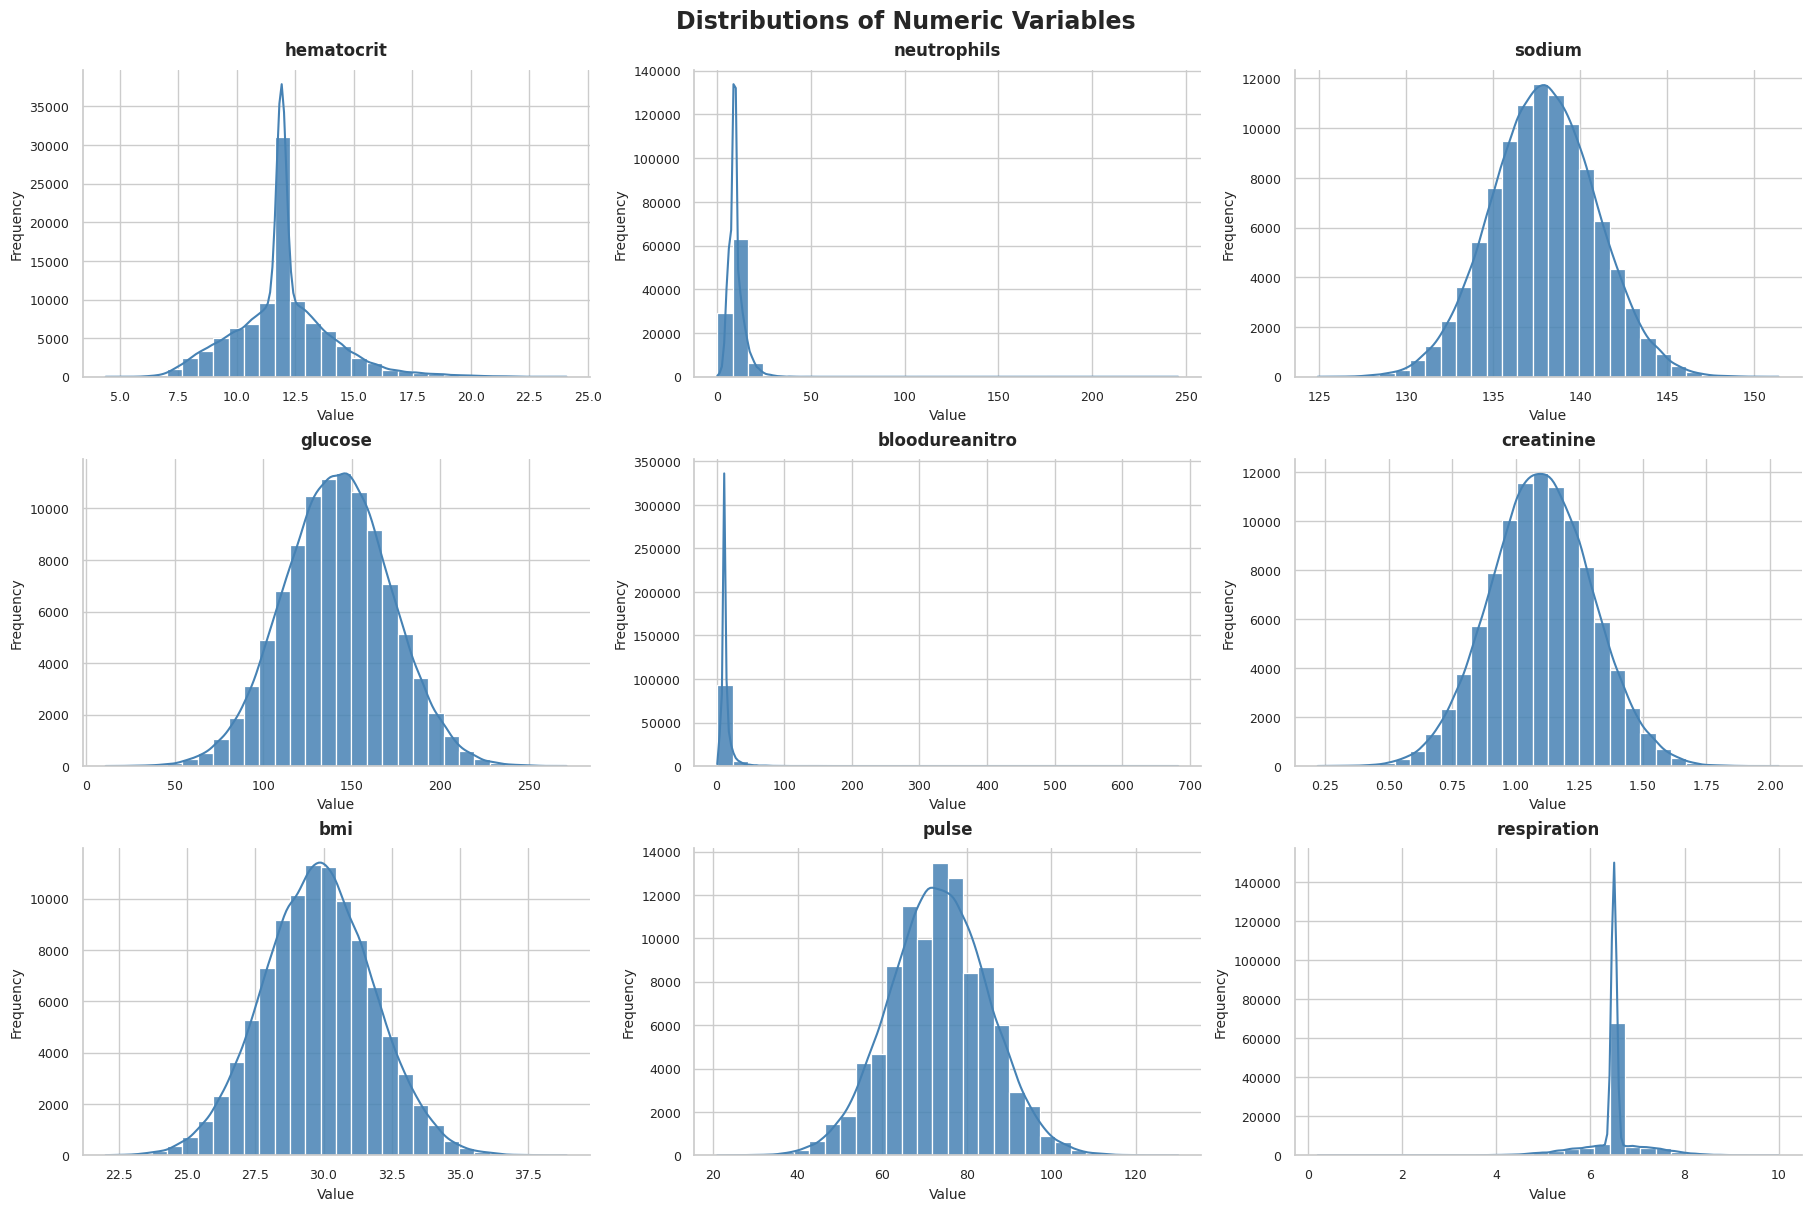

In [ ]:
n_cols = 3
n_rows = math.ceil(len(los_numeric_cols) / n_cols)

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(18, 4 * n_rows),
    constrained_layout=True
)

axes = axes.flatten()

for ax, col in zip(axes, los_numeric_cols):
    data = df[col].dropna()

    sns.histplot(
        data=data,
        bins=30,
        kde=True,
        ax=ax,
        color="steelblue",
        edgecolor="white",
        alpha=0.85
    )

    ax.set_title(col, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Value", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.tick_params(axis="both", labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in axes[len(los_numeric_cols):]:
    ax.set_visible(False)

fig.suptitle(
    "Distributions of Numeric Variables",
    fontsize=17,
    fontweight="bold"
)

plt.show()


The plots cover the 9 continuous measurements only. Binary flags, the identifier and the target are excluded because box plots and histograms are not informative for them.

In [ ]:
q1, q3 = df[numerical_cols].quantile(0.25), df[numerical_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = pd.DataFrame({
    'lower_fence': lower, 'upper_fence': upper,
    'n_low': (df[numerical_cols] < lower).sum(),
    'n_high': (df[numerical_cols] > upper).sum(),
    'p99': df[numerical_cols].quantile(0.99), 'max': df[numerical_cols].max(),
})
outliers['pct_outliers'] = ((outliers['n_low'] + outliers['n_high']) / len(df) * 100).round(2)
outliers.round(2).sort_values('pct_outliers', ascending=False)

,lower_fence,upper_fence,n_low,n_high,p99,max,pct_outliers
respiration,6.50,6.50,17580,17587,8.20,10.00,35.17
bloodureanitro,6.50,18.50,6462,13130,53.00,682.50,19.59
neutrophils,2.00,17.20,322,6193,25.00,245.90,6.52
hematocrit,7.90,15.90,1855,3761,18.20,24.10,5.62
pulse,43.50,103.50,537,517,101.00,130.00,1.05
sodium,129.81,145.98,359,352,144.86,151.39,0.71
glucose,60.94,222.93,368,326,211.16,271.44,0.69
bmi,24.40,35.21,321,364,34.45,38.94,0.69
creatinine,0.56,1.64,343,332,1.56,2.04,0.68


We compare the LOS for outliers and for the other values.

In [ ]:
pd.DataFrame({
    'mean LOS (outliers)': [df.loc[(df[c] < lower[c]) | (df[c] > upper[c]), target].mean() for c in numerical_cols],
    'mean LOS (others)': [df.loc[(df[c] >= lower[c]) & (df[c] <= upper[c]), target].mean() for c in numerical_cols],
}, index=numerical_cols).round(2)

,mean LOS (outliers),mean LOS (others)
hematocrit,4.84,3.95
neutrophils,4.67,3.95
sodium,4.64,4.00
glucose,4.53,4.00
bloodureanitro,4.85,3.79
creatinine,4.45,4.00
bmi,4.56,4.00
pulse,4.57,3.99
respiration,4.82,3.55


**Decision for each feature:**

| Feature | Finding | Decision |
|---|---|---|
| `neutrophils` | Long right tail, max 245.9 vs 99th percentile 25 | Cap at the 1st/99th percentiles |
| `bloodureanitro` | Long right tail, max 682.5 vs 99th percentile 53 | Cap at the 1st/99th percentiles |
| `hematocrit`, `sodium`, `glucose`, `creatinine`, `bmi`, `pulse` | Flagged values are possible clinical values within a near-symmetric distribution | Retain |
| `respiration` | 35% "outliers" only because 65% of values sit exactly at 6.5, which makes the IQR tiny | Retain (the IQR rule is misleading here) |

We do not remove rows. The extreme values are clinically possible, and the table above shows that patients with outlying values stay roughly 0.5 to 1.3 days longer on average for every measurement. These patients are exactly the
ones the model needs to learn about. Deleting them would bias the model toward
healthy, short-stay patients. Capping the two heavy-tailed labs keeps the patients but stops a handful of extreme readings from dominating linear models.

## 6. Target variable exploration
Analyze the target variable and its distribution. For classification tasks check class balance, for regression tasks check range, skewness, variance, and correlation analysis. Find which variables may be most informative and which relationships appear weak or noisy.

In [ ]:
df['lengthofstay'].value_counts()

,count
lengthofstay,
1,17979
3,16068
4,14822
2,12825
5,12116
6,10362
7,7262
8,4652
9,2184


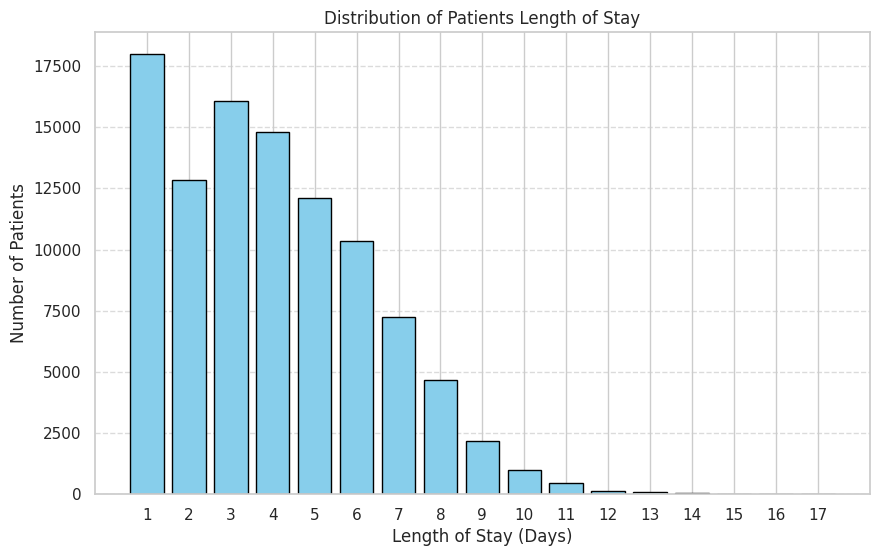

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['lengthofstay'], bins=range(1, df['lengthofstay'].max() + 2), align='left', rwidth=0.8, color='skyblue', edgecolor='black')
plt.title('Distribution of Patients Length of Stay')
plt.xlabel('Length of Stay (Days)')
plt.ylabel('Number of Patients')
plt.xticks(range(1, df['lengthofstay'].max() + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

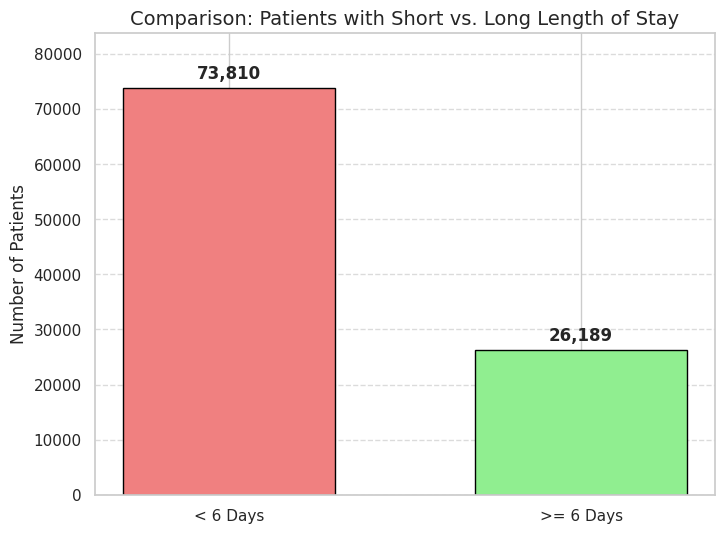

In [ ]:
import matplotlib.pyplot as plt

# Calculate counts
less_than_6 = (df['lengthofstay'] < 6).sum()
greater_equal_6 = (df['lengthofstay'] >= 6).sum()

# Plot comparison
categories = ['< 6 Days', '>= 6 Days']
counts = [less_than_6, greater_equal_6]

plt.figure(figsize=(8, 6))
bars = plt.bar(categories, counts, color=['lightcoral', 'lightgreen'], edgecolor='black', width=0.6)

# Add counts on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f'{yval:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Comparison: Patients with Short vs. Long Length of Stay', fontsize=14)
plt.ylabel('Number of Patients', fontsize=12)
plt.ylim(0, max(counts) + 10000)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df['long_stay'] = (df[target] >= 6).astype(int)
df['long_stay'].value_counts().rename({0: '< 6 days', 1: '>= 6 days'}).to_frame('count') \
    .assign(pct=lambda t: (t['count'] / len(df) * 100).round(1))

,count,pct
long_stay,,
< 6 days,73810,73.8
>= 6 days,26189,26.2


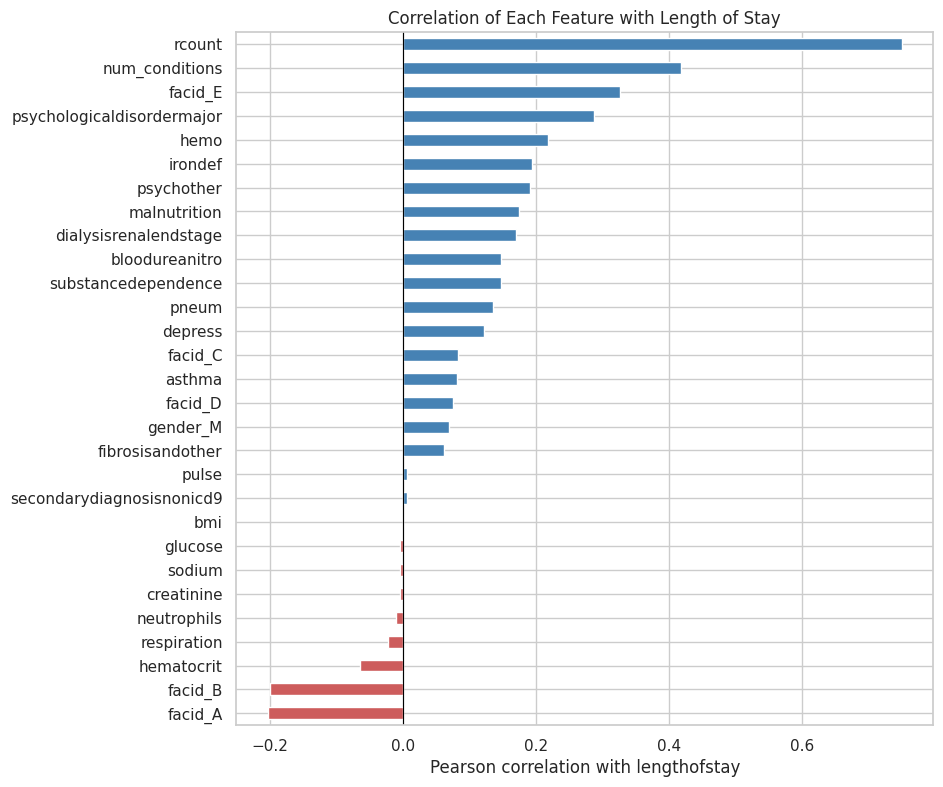

In [ ]:
corr_df = df.drop(columns=id_cols + temporal_cols+ ['long_stay']).copy()
corr_df['gender_M'] = (corr_df.pop('gender') == 'M').astype(int)
corr_df = pd.get_dummies(corr_df, columns=['facid'], dtype=int)
corr_df['num_conditions'] = df[flag_cols].sum(axis=1)

target_corr = corr_df.corr()[target].drop(target).sort_values()

fig, ax = plt.subplots(figsize=(9, 9))
colors = ['indianred' if v < 0 else 'steelblue' for v in target_corr]
target_corr.plot.barh(ax=ax, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Pearson correlation with lengthofstay')
ax.set_title('Correlation of Each Feature with Length of Stay')
plt.show()

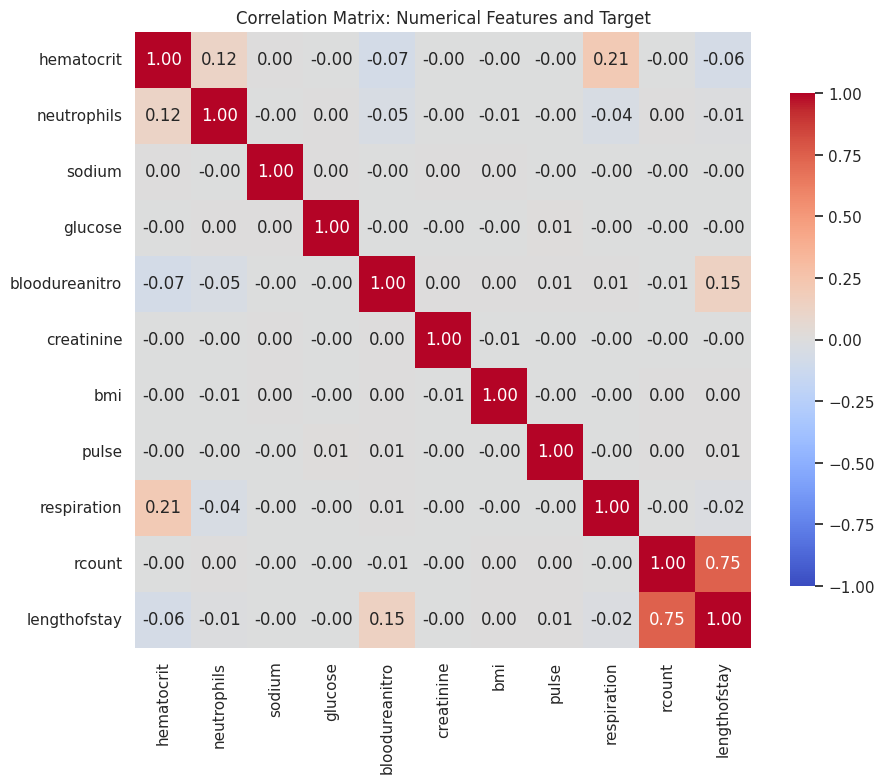

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols + ['rcount', target]].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix: Numerical Features and Target')
plt.show()

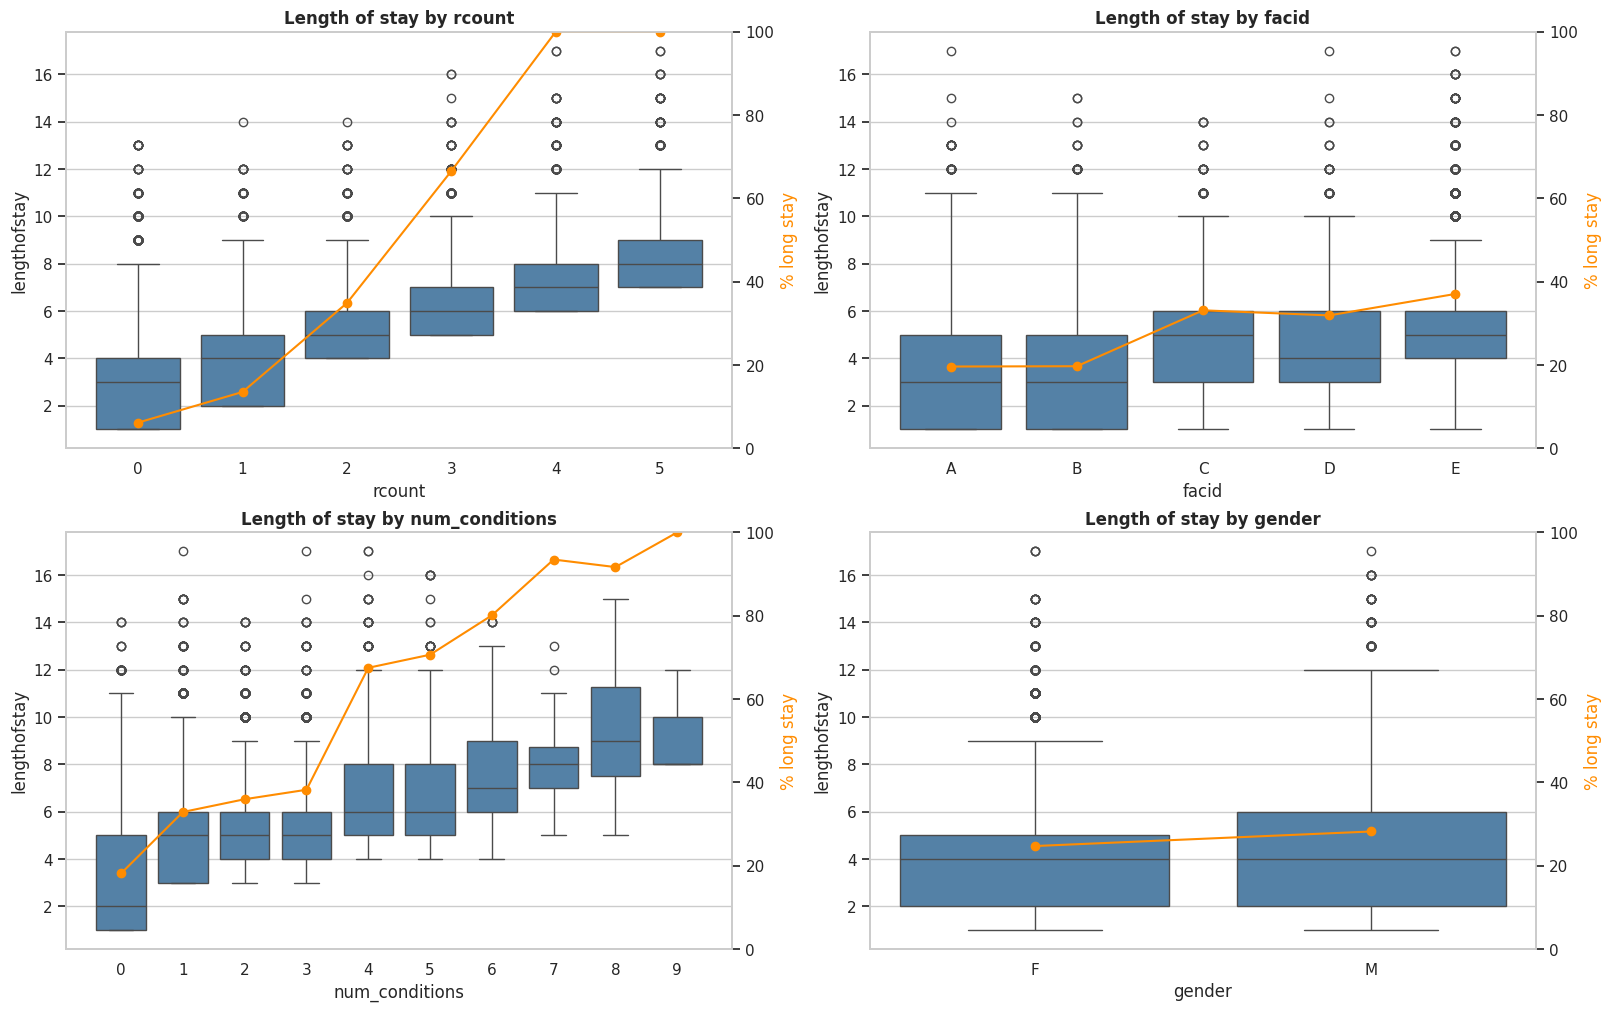

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
df_plot = df.assign(num_conditions=df[flag_cols].sum(axis=1))
for ax, col in zip(axes.flat, ['rcount', 'facid', 'num_conditions', 'gender']):
    order = sorted(df_plot[col].unique())
    sns.boxplot(data=df_plot, x=col, y=target, order=order, ax=ax, color='steelblue')
    ax2 = ax.twinx()
    rate = df_plot.groupby(col)['long_stay'].mean().reindex(order) * 100
    ax2.plot(range(len(order)), rate.values, color='darkorange', marker='o')
    ax2.set_ylabel('% long stay', color='darkorange')
    ax2.set_ylim(0, 100)
    ax2.grid(False)
    ax.set_title(f'Length of stay by {col}', fontweight='bold')
plt.show()

- rcount is the strongest predictor ( r = 0.75 )
- Number of conditions(r=0.42). Patient with more flagged conditions stay longer. Every condition adds around 1-2 days.
- Facilities C, D and E average about 5 days against about 3.3 at A and B, so facility is a clear signal.
- bloodureandnitro and hematocrit carry some significance.

In [ ]:
flag_effect = pd.DataFrame({
    'percentage%': df[flag_cols].mean() * 100,
    'LOS_with': [df.loc[df[c] == 1, target].mean() for c in flag_cols],
    'LOS_without': [df.loc[df[c] == 0, target].mean() for c in flag_cols],
})
flag_effect['difference'] = flag_effect['LOS_with'] - flag_effect['LOS_without']
flag_effect.round(2).sort_values('difference', ascending=False)

,percentage%,LOS_with,LOS_without,difference
dialysisrenalendstage,3.64,6.06,3.92,2.14
fibrosisandother,0.48,6.11,3.99,2.12
psychother,4.94,5.99,3.90,2.09
malnutrition,4.95,5.81,3.91,1.90
hemo,8.00,5.74,3.85,1.89
pneum,3.95,5.58,3.94,1.64
psychologicaldisordermajor,23.90,5.21,3.62,1.59
irondef,9.49,5.41,3.85,1.56
substancedependence,6.31,5.35,3.91,1.44
depress,5.17,5.23,3.93,1.29


## 7. Data preprocessing
Summarize EDA findings and finalize preprocessing and feature engineering to prepare the dataset for the next phase of machine learning modeling

### Creating target variable for the classification problem
As discussed ealier, 6 days is the industry max number of days. If a patient stays more than that it is considered an overstay.

We will use lengthofstay to create a target variable for our classification problem to predict probability of overstaying at a hospital

In [ ]:
(df['lengthofstay'] >= 6).sum()

np.int64(26189)

In [ ]:
(df['lengthofstay']< 6).sum()

np.int64(73810)

In [ ]:
df.columns

Index(['eid', 'vdate', 'rcount', 'gender', 'dialysisrenalendstage', 'asthma',
       'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor',
       'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo',
       'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro',
       'creatinine', 'bmi', 'pulse', 'respiration',
       'secondarydiagnosisnonicd9', 'discharged', 'facid', 'lengthofstay',
       'long_stay'],
      dtype='object')

In [ ]:
df.head()

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,malnutrition,hemo,hematocrit,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay,long_stay
0,1,2012-08-29,0,F,0,0,0,0,0,0,0,0,0,0,0,11.5,14.20,140.361132,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3,0
1,2,2012-05-26,5,F,0,0,0,0,0,0,0,0,0,0,0,9.0,4.10,136.731692,94.078507,8.0,0.943164,28.460516,61,6.5,1,2012-06-02,A,7,1
2,3,2012-09-22,1,F,0,0,0,0,0,0,0,0,0,0,0,8.4,8.90,133.058514,130.530524,12.0,1.065750,28.843812,64,6.5,2,2012-09-25,B,3,0
3,4,2012-08-09,0,F,0,0,0,0,0,0,0,0,0,0,0,11.9,9.40,138.994023,163.377028,12.0,0.906862,27.959007,76,6.5,1,2012-08-10,A,1,0
4,5,2012-12-20,0,F,0,0,0,1,0,1,0,0,0,0,0,9.1,9.05,138.634836,94.886654,11.5,1.242854,30.258927,67,5.6,2,2012-12-24,E,4,0


In [ ]:
# if lengthofstay > 6 -> 1
#    lengthofstay <= 6 -> 0
df['long_stay'] = (df[target] >= 6).astype(int)


### Categorical Encoding

In [ ]:
df['rcount'].unique()

array([0, 5, 1, 3, 4, 2])

In [ ]:
df['rcount'].replace('5+', '5').astype(int)

,rcount
0,0
1,5
2,1
3,0
4,0
...,...
99994,3
99995,0
99996,1
99997,0


In [ ]:
# Encode gender as 0 and 1 and one hot encoding facid
df['gender'] = df['gender'].map({'F': 0, 'M': 1})
df = pd.get_dummies(df, columns=['facid'], dtype=int)

In [ ]:
# Dropping features we think will have less importance in prediction
length_of_stay_features = df.drop(columns=['eid','vdate','discharged'])

### Creating Train, Test and Validation datasets

Dataset split:
- 70% Training: Used to train the model.
- 15% Validation: Used to tune hyperparameters and select the best model.
- 15% Testing: Used for the final evaluation of model performance.

#### Data split for the regression model
 We are predicting **lengthofstay** in days

In [ ]:
from sklearn.model_selection import train_test_split

X_regr = length_of_stay_features.drop(
    columns=['lengthofstay', 'long_stay']
)
y_regr = length_of_stay_features['lengthofstay']

X_regr_train, X_regr_hold, y_regr_train, y_regr_hold = train_test_split(
    X_regr, y_regr, test_size=0.3
)

X_regr_val, X_regr_test, y_regr_val, y_regr_test = train_test_split(
    X_regr_hold, y_regr_hold, test_size=0.5
)

print("Training set:", X_regr_train.shape, y_regr_train.shape)
print("Validation set:", X_regr_val.shape, y_regr_val.shape)
print("Test set:", X_regr_test.shape, y_regr_test.shape)

Training set: (69999, 28) (69999,)
Validation set: (15000, 28) (15000,)
Test set: (15000, 28) (15000,)


In [ ]:
X_regr_train.head()

,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,malnutrition,hemo,hematocrit,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,facid_A,facid_B,facid_C,facid_D,facid_E
55048,0,0,0,1,0,0,0,0,1,0,0,0,0,12.5,5.7,141.243383,164.936652,6.0,0.597100,28.034592,65,6.2,1,0,0,0,1,0
85647,1,1,0,0,1,0,0,1,1,0,0,0,0,14.8,6.5,137.839463,110.585793,20.0,1.023505,30.235962,69,8.0,9,0,0,0,0,1
30722,3,0,0,0,0,0,0,0,0,0,0,0,0,11.6,7.9,138.648747,168.671309,17.0,1.283665,32.237974,57,6.5,0,1,0,0,0,0
68466,4,1,0,0,0,0,0,0,0,0,0,0,0,11.9,9.4,135.994725,102.166868,12.0,1.421238,33.166173,68,6.5,1,1,0,0,0,0
21518,0,1,0,0,0,0,0,1,0,0,0,0,0,11.9,9.4,137.067583,126.714261,12.0,0.856176,28.291091,84,6.5,1,0,0,0,0,1


In [ ]:
y_regr_train.head()

,lengthofstay
55048,3
85647,5
30722,5
68466,8
21518,3


#### Data split for the Classification model
 We are predicting the probability of a patient overstaying in hospital **long_stay** in days

In [ ]:
from sklearn.model_selection import train_test_split

X_class = length_of_stay_features.drop(
    columns=['lengthofstay', 'long_stay']
)
y_class = length_of_stay_features['long_stay']

X_class_train, X_class_hold, y_class_train, y_class_hold = train_test_split(
    X_class, y_class, test_size=0.3
)

X_class_val, X_class_test, y_class_val, y_class_test = train_test_split(
    X_class_hold, y_class_hold, test_size=0.5
)

print("Training set:", X_class_train.shape, y_class_train.shape)
print("Validation set:", X_class_val.shape, y_class_val.shape)
print("Test set:", X_class_test.shape, y_class_test.shape)

Training set: (69999, 28) (69999,)
Validation set: (15000, 28) (15000,)
Test set: (15000, 28) (15000,)


In [ ]:
X_class_train.head()

,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,malnutrition,hemo,hematocrit,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,facid_A,facid_B,facid_C,facid_D,facid_E
62000,1,1,0,0,0,0,0,1,0,0,0,0,0,7.5,12.10,138.182209,167.133620,7.0,1.063427,26.369848,85,5.6,4,0,0,0,0,1
2397,0,1,0,0,0,0,0,0,0,0,0,0,0,17.4,20.05,139.038943,171.586640,12.0,0.466397,32.726576,60,6.5,4,1,0,0,0,0
41886,1,0,0,0,0,0,0,0,0,0,0,0,0,13.4,13.70,139.041785,127.106393,12.0,1.151437,30.197519,78,6.5,3,0,1,0,0,0
91131,0,1,0,0,0,0,0,0,0,0,0,0,0,12.0,9.30,144.349404,84.211386,12.0,1.090132,29.130996,67,6.5,0,0,1,0,0,0
87369,0,0,0,0,0,0,0,1,0,0,0,0,0,12.5,12.60,144.230536,132.056346,12.0,1.345012,33.072475,64,6.5,3,0,0,0,0,1


In [ ]:
y_class_test.head()

,long_stay
16851,1
61599,0
13989,0
33608,1
17298,0


For this project we have enough data to start building our regression model. The dataset is successfully split into 70% training (70,000 rows), 15% validation (15,000 rows), and 15% testing (15,000 rows).

Each set contains 28 input features and a corresponding target variables, `lengthofstay` and `long_stay`. This split allows the model to learn from the training data, tune its performance using the validation data, and evaluate its final performance on unseen test data.